# Визначення походження тексту

Класи `human`, `ai`, `fusion`; англійська й німецька. Моделі порівнюються на тих самих 40 000 навчальних документах, трьох групових розбиттях і фіксованому контролі з 54 469 документів. Метрика — macro-F1.

## Відтворення

README містить завантаження даних через Kaggle CLI, створення груп, підготовку фіксованої вибірки та запуск Colab. `classical_experiments.py` і `transformer_experiments.py` містять повний код навчання. `finalize_experiments.py` обирає модель за CV та перевіряє передбачення. Цей ноутбук читає фактичні збережені результати.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
def load(name):
    return json.loads((ROOT / 'results' / name).read_text())
metrics = load('final_metrics.json')
audit = load('data_audit.json')

## Дані та розбиття

Точних повторів не виявлено. Лексично близькі тексти об'єднано через MinHash LSH і точний поріг схожості Жаккара 0,65. Початкові джерельні ID невідомі; сильні перефразування можуть бути пропущені.

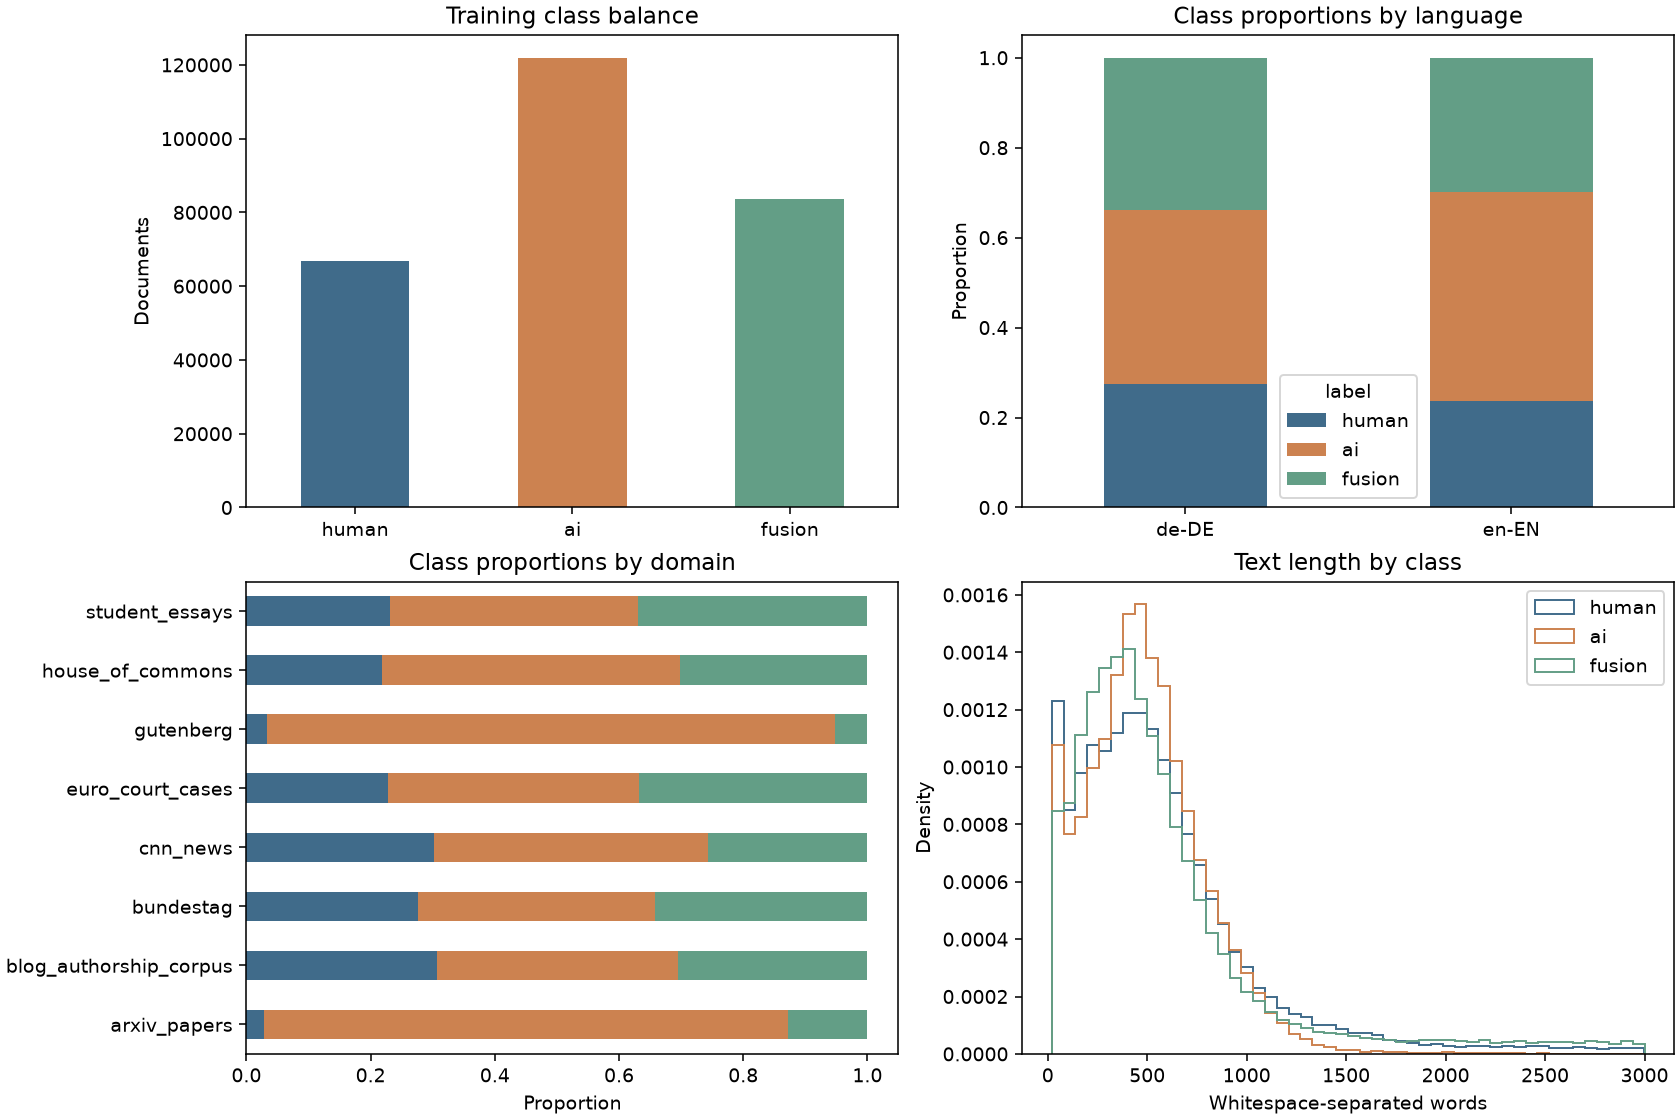

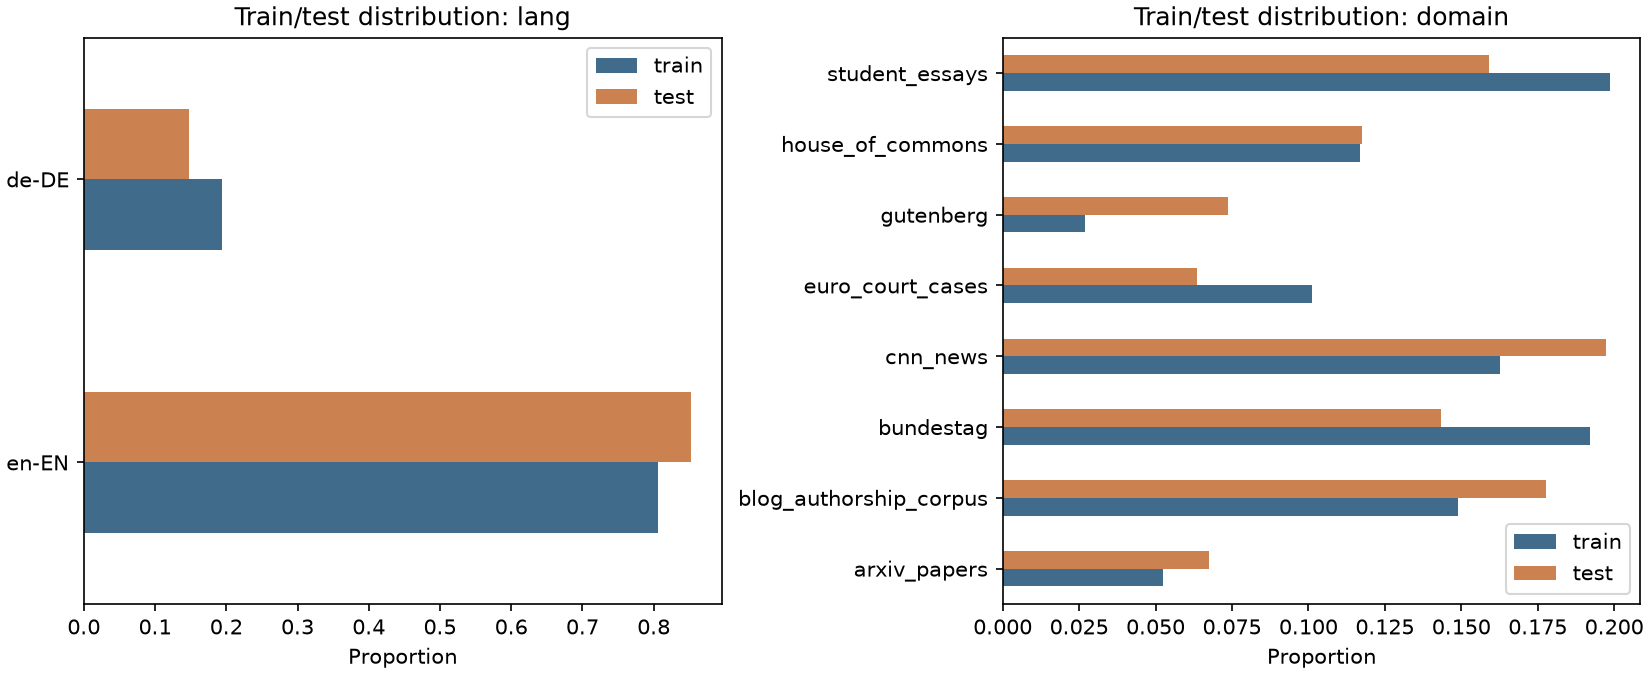

,значення
seed,42
folds,5
holdout_fold,0
manifest_sha256,410ff2df025ec00051bab0b0656a01a4711fb90f4d9f48...
grouping,64-permutation MinHash LSH candidates; exact w...
candidate_pairs_checked,89918
verified_pairs,35600
cross_domain_pairs,104
cross_language_pairs,5
groups,244376


In [2]:
display(Image(filename=str(ROOT / 'results' / 'eda.png')))
display(Image(filename=str(ROOT / 'results' / 'train_test_shift.png')))
display(pd.Series(load('split_audit.json')).drop(['limitations']).to_frame('значення'))

### Приклади класів

Перші уривки по одному для кожної комбінації мови й класу. Мітки взяті з train.csv. Уривок `fusion` може не містити переписаної частини; за коротким початком не можна встановлювати походження всього документа.

In [3]:
examples = {}
for chunk in pd.read_csv(ROOT / 'data' / 'train.csv', chunksize=1000):
    for row in chunk.itertuples():
        key = (row.lang, row.label)
        if key not in examples:
            examples[key] = ' '.join(row.text.split())[:350]
    if len(examples) == 6:
        break
for (lang, label), excerpt in sorted(examples.items()):
    print(lang, label)
    display(pd.DataFrame({'Уривок': [excerpt]}).style.format(escape='html').set_properties(**{'white-space':'normal'}))

de-DE ai


,Уривок
0,"Liebe Gäste, meine Damen und Herren, heute steht vor uns ein wichtiges Thema: der Haushalt des Bundesministeriums für Gesundheit für das kommende Jahr. Dieser Haushalt spiegelt unsere tiefe Verpflichtung wider, die Gesundheit aller Bürgerinnen und Bürger dieses Landes zu gewährleisten und gleichzeitig unseren Beitrag zum globalen Gesundheitssystem"


de-DE fusion


,Уривок
0,"Sehr geehrte Frau Präsidentin! Liebe Kolleginnen und Kollegen! 84 Prozent der Beschäftigten in der IT-Branche in Deutschland sind Männer. 84 Prozent! Gerade einmal zwei von zehn Start-ups werden von Frauen gegründet. Selbst wenn der Zugang gelingt, verlassen mehr als 50 Prozent der Frauen die Digitalbranche wieder, im Topmanagement findet man auch"


de-DE human


,Уривок
0,"Herr Präsident! Meine Damen und Herren! Es wird Sie nicht völlig verwundern, wenn ich nach drei Jahren Regierungszeit, nachdem drei Viertel dieser Regierungszeit vergangen sind, positive Bilanz ziehe für den Bundesinnenminister, gerade für die Felder Migration und innere Sicherheit. Ich will das an ganz konkreten Punkten festmachen. Fachkräfteeinwa"


... (2 outputs left out)

en-EN fusion


,Уривок
0,urlLink First footage of the new Bat Mobile from the new movie 'Batman Begins'! That looks SOOOOO sweet. The sleek design promises to redefine what we expect from Gotham's protector.


en-EN human


,Уривок
0,"[12/17/2002 9:40:16 PM | + racheal] shagging. I feel sick. I want to go throw up and throw up and throw up. I dont know what it isremnants of dinner flushed down with red wine and biscotti feels trapped in my throat. But thats the way it always feel, thats the way the story goes. Right before I do myself the glorious perverse pleasure of pumping th"


## Перевірені гіпотези

1. Символьні фрагменти 3–5 знаків можуть допомагати розрізняти `human` і `fusion`. Їх порівняно зі словами за однакового C=4.
2. Для того самого донавченого DistilBERT порівняно початок документа та середні ймовірності за початком, серединою й кінцем. Це перевірка додаткового контексту під час передбачення, без окремого донавчання на фрагментах.

Енкодер: одна епоха, 256 токенів, LR=3e-5, batch=16, накопичення=2, FP16. Фактичний пристрій і версії наведені в конфігурації нижче.

In [4]:
display(pd.Series(load('transformer_config.json')).to_frame('налаштування'))
display(pd.Series(load('development_tokenization.json')).to_frame('токенізація'))

,налаштування
model,distilbert/distilbert-base-multilingual-cased
revision,45c032ab32cc946ad88a166f7cb282f58c753c2e
epochs,1
sequence_length,256
batch_size,16
gradient_accumulation,2
learning_rate,0.00003
class_order,"[human, ai, fusion]"
gpu,Tesla T4
torch,2.14.1+cu130


,токенізація
rows,40000
sequence_length,256
content_tokens_per_chunk,254
median_full_tokens,666.0
max_full_tokens,11456
fraction_exceeding_one_chunk,0.846925
mean_head_coverage,0.482242
mean_three_chunk_coverage,0.867745
limitations,Up to three non-overlapping/overlapping window...


## Порівняння моделей

CV використовується для вибору параметрів і ваг; контрольні оцінки наведені окремо. Стандартне відхилення трьох оцінок не є довірчим інтервалом. Вибраний CV-результат не є незалежною вкладеною оцінкою.

,model,CV macro-F1,CV SD,holdout macro-F1
0,word,0.8454,0.0026,0.8516
1,character,0.8630,0.0019,0.8659
2,classical_blend,0.8654,0.0032,0.8700
3,transformer_head,0.7483,0.0042,0.7657
4,transformer_chunks,0.7755,0.0090,0.8068
5,ensemble,0.8739,0.0038,0.8784


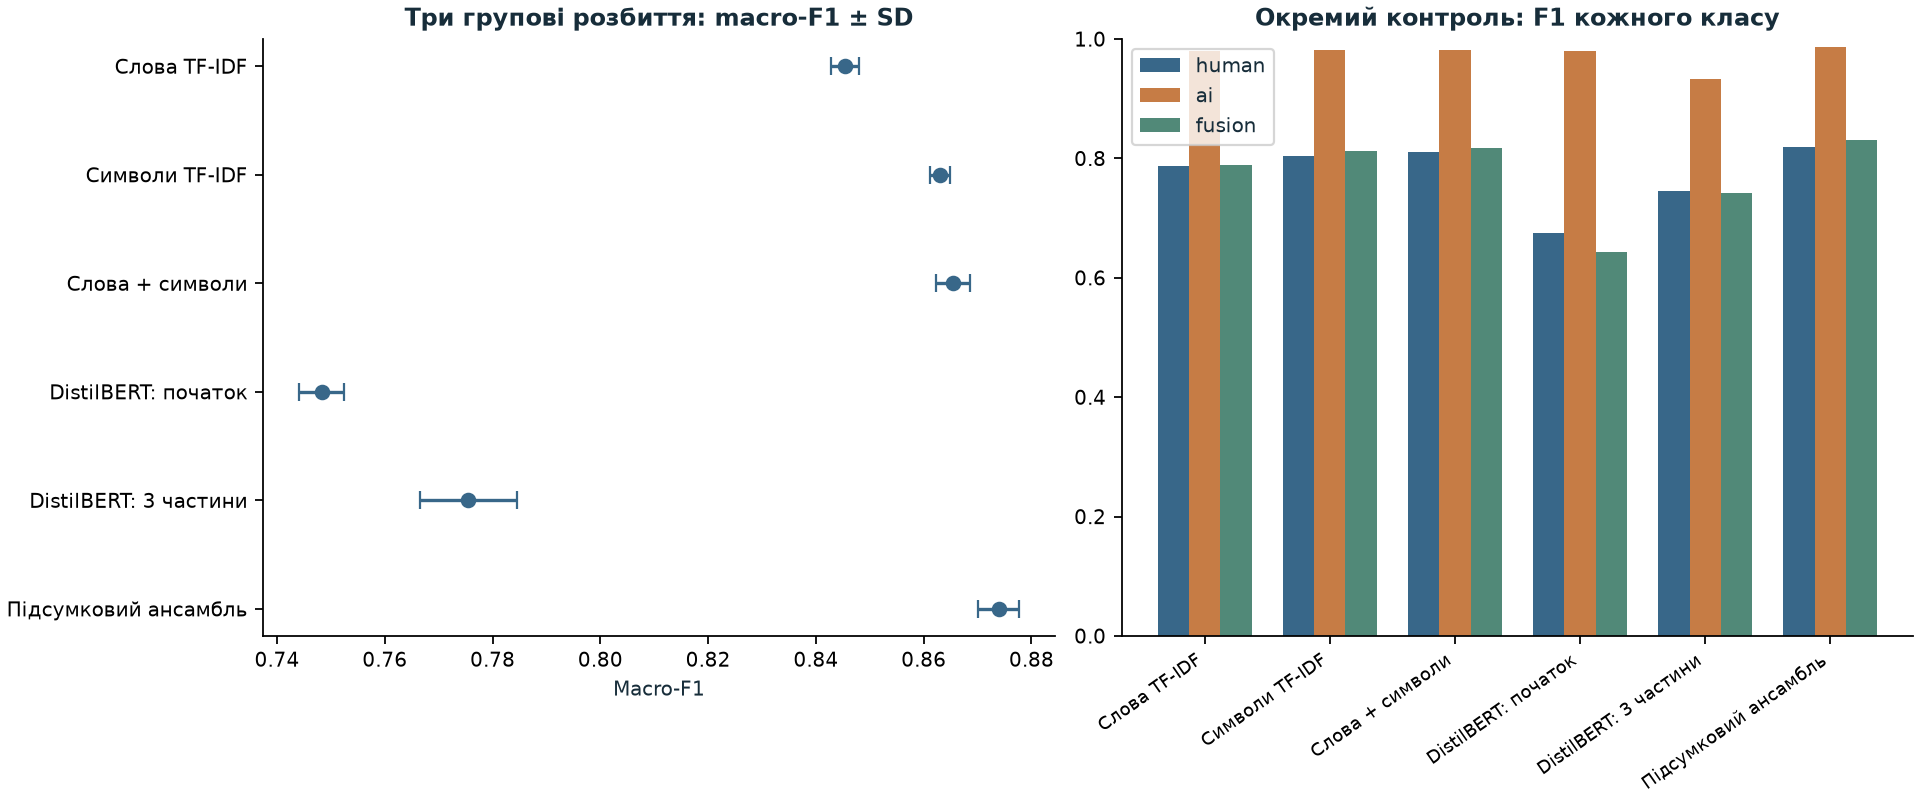

,результат
character_cv_delta,0.017599
chunking_cv_delta,0.027244
character_supported_in_this_configuration,True
chunking_supported_in_this_configuration,True


In [5]:
display(pd.DataFrame([{
    'model': name, 'CV macro-F1': row['cv_mean'],
    'CV SD': row['cv_std'], 'holdout macro-F1': row['holdout_macro_f1']
} for name, row in metrics['models'].items()]).round(4))
display(Image(filename=str(ROOT / 'results' / 'final_comparison.png')))
display(pd.Series(load('hypotheses.json')).to_frame('результат'))

## Помилки та підгрупи

Окремі результати за мовами й джерелами допомагають помітити нерівномірну якість. Їхні розміри й баланси класів відрізняються.

,precision,recall,f1-score,support
human,0.7812,0.8593,0.8184,13343.0
ai,0.9814,0.9915,0.9864,24389.0
fusion,0.8740,0.7911,0.8305,16737.0
macro avg,0.8788,0.8807,0.8784,54469.0


,human,ai,fusion
human,11466,91,1786
ai,84,24182,123
fusion,3128,368,13241


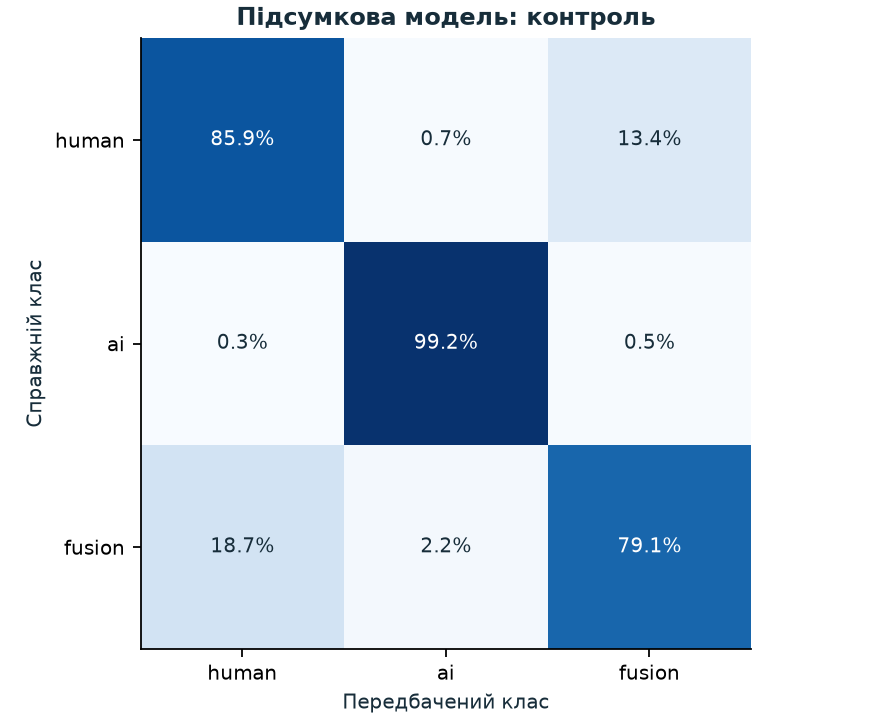

,slice,value,rows,macro_f1
0,lang,de-DE,10552,0.9028
1,lang,en-EN,43917,0.8718
2,domain,arxiv_papers,2858,0.8539
3,domain,blog_authorship_corpus,8110,0.7613
4,domain,bundestag,10470,0.9032
5,domain,cnn_news,8858,0.9003
6,domain,euro_court_cases,5516,0.9078
7,domain,gutenberg,1465,0.6852
8,domain,house_of_commons,6372,0.8784
9,domain,student_essays,10820,0.9008


In [6]:
selected = metrics['models'][metrics['selected_model']]
display(pd.DataFrame({k: selected['holdout_report'][k] for k in ['human','ai','fusion','macro avg']}).T.round(4))
display(pd.DataFrame(selected['holdout_confusion'], index=['human','ai','fusion'], columns=['human','ai','fusion']))
display(Image(filename=str(ROOT / 'results' / 'final_confusion.png')))
display(pd.DataFrame(selected['holdout_slices']).round(4))

## Пояснюваність

Для символьної моделі обчислено точний внесок TF-IDF-ознак у різницю оцінок передбаченого та другого класів. Перевірено, що сума внесків і зсуву відтворює цю різницю. Це локальне лінійне пояснення компонента; ознаки не доводять причинний механізм авторства.

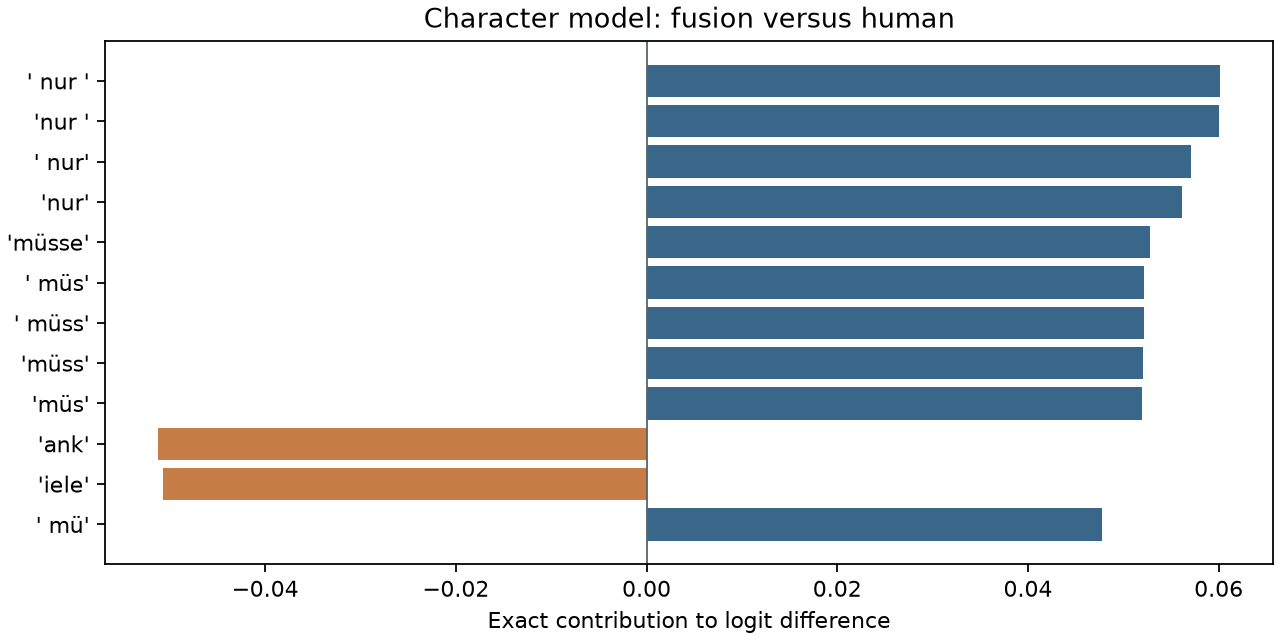

Обрана модель: ensemble


,model,file,rows,sha256,cv_macro_f1
0,ensemble,ensemble-cv-selected.csv,25000,ad2d27e977bd78865f393ca3c44c3f39b5f83c69e4eee2...,0.873886
1,character,character-cv-selected.csv,25000,1894be5d3fae29a0fc3ba882f32896bad3e4286469f76b...,0.863021


In [7]:
display(Image(filename=str(ROOT / 'results' / 'character_attribution.png')))
print('Обрана модель:', metrics['selected_model'])
display(pd.DataFrame(metrics['submission_files']))

## Обмеження та джерела

Навчання на підвибірці, одна епоха енкодера, наближені джерельні групи та неповне покриття найдовших документів обмежують висновки. Public leaderboard не замінює незалежну перевірку.

[Kaggle HW3](https://www.kaggle.com/competitions/ai-generated-text-detection-hw3-ucu-ai-2026), [scikit-learn](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction), [DistilBERT](https://huggingface.co/distilbert/distilbert-base-multilingual-cased), [datasketch](https://ekzhu.com/datasketch/documentation.html).